# Phase 2 Continuation — Real Execution (Weeks 1-7 of the approved plan)

This notebook executes, for real, the plan laid out in `phase2/CONTINUATION_EXEMPLAR_REPORT.md`:
reproduction check, real error-analysis validation of the "boundary detail" hypothesis, a
designed architecture change ("Model D"), and a follow-up L2 refinement -- each confirmed
across 3 seeds. **No test-set files are loaded anywhere in this notebook.** Week 8 (the final,
once-only test evaluation) is deliberately NOT performed here -- it requires explicit approval
per the project's established rule, and is left for a separate step.

All numbers below are real, computed outputs -- nothing here is illustrative.


In [1]:
import os
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["PYTHONHASHSEED"] = "42"

import random, csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndi
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

tf.config.experimental.enable_op_determinism()

DATA_DIR = Path(".")
P2_MODELS = Path("phase2/models")
P2_FIGURES = Path("phase2/figures")
P2_RESULTS = Path("phase2/results")
for d in (P2_MODELS, P2_FIGURES, P2_RESULTS):
    d.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)


I0000 00:00:1788107556.538810   35428 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1788107557.610561   35428 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788107560.303919   35428 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


In [2]:
train_images = np.load(DATA_DIR / "train_images.npy")
train_labels = np.load(DATA_DIR / "train_labels.npy").flatten()
val_images = np.load(DATA_DIR / "val_images.npy")
val_labels = np.load(DATA_DIR / "val_labels.npy").flatten()
# test_images.npy / test_labels.npy: DELIBERATELY NOT loaded anywhere in this notebook.

def preprocess_images(images):
    images = images.astype("float32") / 255.0
    return np.expand_dims(images, axis=-1)

X_train, y_train = preprocess_images(train_images), train_labels.astype("int32")
X_val, y_val = preprocess_images(val_images), val_labels.astype("int32")

classes_sorted = sorted(np.unique(y_train))
n_classes = len(classes_sorted)
idx1, idx2 = classes_sorted.index(1), classes_sorted.index(2)

def evaluate_on_val(model):
    probs = model.predict(X_val, verbose=0)
    preds = np.argmax(probs, axis=1)
    acc = accuracy_score(y_val, preds)
    mp, mr, mf1, _ = precision_recall_fscore_support(y_val, preds, average="macro", zero_division=0)
    p, r, f1, sup = precision_recall_fscore_support(y_val, preds, average=None, zero_division=0, labels=classes_sorted)
    cm = confusion_matrix(y_val, preds, labels=classes_sorted)
    return dict(probs=probs, preds=preds, acc=acc, macro_p=mp, macro_r=mr, macro_f1=mf1, per_p=p, per_r=r, per_f1=f1, sup=sup, cm=cm)

print("Setup complete.")


Setup complete.


## Week 1 — Reproduction Check

Rather than retrain (the checkpoint already exists and retraining it would not be a new
result), the existing Phase 1 baseline checkpoint is reloaded read-only and re-evaluated on
validation, to confirm it still falls inside the documented noise band before anything new is
attempted.


In [3]:
model_a = keras.models.load_model("models/model_a_baseline_best.keras")
res_baseline = evaluate_on_val(model_a)
print(f"Baseline reload check: Accuracy={res_baseline['acc']:.4f}  Macro F1={res_baseline['macro_f1']:.4f}")
NOISE_LOW, NOISE_HIGH = 0.797, 0.817
in_band = NOISE_LOW <= res_baseline["macro_f1"] <= NOISE_HIGH
print(f"Inside documented noise band [{NOISE_LOW}, {NOISE_HIGH}]? {in_band}")


E0000 00:00:1788107564.338875   35428 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


E0000 00:00:1788107564.685358   35428 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Baseline reload check: Accuracy=0.8907  Macro F1=0.8053
Inside documented noise band [0.797, 0.817]? True


## Week 2 — Error Analysis and Hypothesis Test

Re-confirming the confusion pattern and confidence finding from the baseline reload, then
running a genuinely new, quick check: does the confusable pair actually show weaker edge
(boundary) structure than other classes, as the "detail lost to pooling" hypothesis requires?
This is a real computation (Sobel gradient magnitude), not an assumption.


In [4]:
confidence = res_baseline["probs"].max(axis=1)
val_preds = res_baseline["preds"]
mask_2as1 = (y_val == 2) & (val_preds == 1)
mask_1as2 = (y_val == 1) & (val_preds == 2)
correct_mask = (val_preds == y_val)

print(f"True class-2 predicted as class-1: {mask_2as1.sum()} / {(y_val==2).sum()}")
print(f"True class-1 predicted as class-2: {mask_1as2.sum()} / {(y_val==1).sum()}")
print(f"Mean confidence, correct predictions: {confidence[correct_mask].mean():.3f}")
print(f"Mean confidence, class-2-as-1 errors: {confidence[mask_2as1].mean() if mask_2as1.sum() else float('nan'):.3f}")


True class-2 predicted as class-1: 94 / 95
True class-1 predicted as class-2: 0 / 104
Mean confidence, correct predictions: 0.937
Mean confidence, class-2-as-1 errors: 0.568


In [5]:
def mean_edge_magnitude(images_uint8):
    mags = []
    for img in images_uint8:
        gx = ndi.sobel(img.astype(np.float64), axis=0)
        gy = ndi.sobel(img.astype(np.float64), axis=1)
        mag = np.hypot(gx, gy)
        mags.append(mag.mean())
    return np.array(mags)

edge_class1 = mean_edge_magnitude(train_images[train_labels == 1])
edge_class2 = mean_edge_magnitude(train_images[train_labels == 2])
other_mask = ~np.isin(train_labels, [1, 2])
edge_other = mean_edge_magnitude(train_images[other_mask][:2000])  # sample for speed

print(f"Mean Sobel edge magnitude -- class 1: {edge_class1.mean():.2f} (n={len(edge_class1)})")
print(f"Mean Sobel edge magnitude -- class 2: {edge_class2.mean():.2f} (n={len(edge_class2)})")
print(f"Mean Sobel edge magnitude -- other classes (2000-sample): {edge_other.mean():.2f}")
print()
pct_diff = 100 * (edge_other.mean() - np.mean([edge_class1.mean(), edge_class2.mean()])) / edge_other.mean()
print(f"Classes 1/2 combined vs other classes: {pct_diff:+.1f}% difference in mean edge magnitude")


Mean Sobel edge magnitude -- class 1: 60.62 (n=630)
Mean Sobel edge magnitude -- class 2: 59.41 (n=614)
Mean Sobel edge magnitude -- other classes (2000-sample): 115.30

Classes 1/2 combined vs other classes: +47.9% difference in mean edge magnitude


**Hypothesis (stated before building anything new):** if classes 1/2 show measurably weaker
boundary/edge structure than other classes, that is consistent with -- though not proof of --
the idea that fine boundary detail matters more for separating this pair, and that the
baseline's three successive 2x2 max-pools may be discarding it prematurely. The architecture
change below (Model D) is motivated by this measured comparison, not assumed in advance.


## Weeks 3-4 — Model D: Detail-Preserving Variant

**Single change vs. baseline:** one additional 3x3 Conv2D(16, relu) inserted before the first
max-pool only. Everything else -- filters in blocks 2-3, dense layer, dropout, optimizer,
learning rate, batch size, loss, no augmentation, no class weighting -- identical to Model A.


In [6]:
def build_model_d(input_shape=(64, 64, 1), n_classes=11, extra_conv_l2=0.0):
    reg = keras.regularizers.l2(extra_conv_l2) if extra_conv_l2 > 0 else None
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), padding="same", activation="relu", name="block1_conv1"),
        layers.Conv2D(16, (3, 3), padding="same", activation="relu",
                       kernel_regularizer=reg, name="block1_conv2_extra"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax"),
    ], name="model_d_detail_preserving")
    return model

_probe = build_model_d()
_probe.summary()
print(f"\nModel D total parameters: {_probe.count_params():,}")


Model: "model_d_detail_preserving"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 64, 64, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2_extra (Conv2D)     │ (None, 64, 64, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 288,539 (1.10 MB)

 Trainable params: 288,539 (1.10 MB)

 Non-trainable params: 0 (0.00 B)


Model D total parameters: 288,539


In [7]:
def log_experiment(row, path):
    fields = ["experiment_id", "seed", "hypothesis", "architecture", "total_params",
               "epochs_run", "best_epoch", "best_val_loss",
               "accuracy", "macro_precision", "macro_recall", "macro_f1",
               "class1_f1", "class2_f1", "class1_recall", "class2_recall", "notes"]
    row = {k: row.get(k, "") for k in fields}
    exists = path.exists()
    with open(path, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        if not exists:
            w.writeheader()
        w.writerow(row)

CONT_LOG = P2_RESULTS / "phase2_continuation_log.csv"
if CONT_LOG.exists():
    CONT_LOG.unlink()  # fresh log for this notebook run

SEEDS = [42, 7, 123]
modeld_results = {}
modeld_histories = {}

for seed in SEEDS:
    print(f"\n{'='*60}\nModel D, seed={seed}\n{'='*60}")
    keras.utils.set_random_seed(seed)
    m = build_model_d(input_shape=X_train.shape[1:], n_classes=n_classes, extra_conv_l2=0.0)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=0),
        keras.callbacks.ModelCheckpoint(str(P2_MODELS / f"modelD_seed{seed}.keras"),
                                         monitor="val_loss", save_best_only=True, verbose=0),
    ]
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=cbs, verbose=2)
    res = evaluate_on_val(m)
    modeld_results[seed] = res
    modeld_histories[seed] = h.history
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    print(f"seed={seed}: acc={res['acc']:.4f}  macro_f1={res['macro_f1']:.4f}  best_epoch={best_epoch}")
    log_experiment({
        "experiment_id": "ModelD (no L2)", "seed": seed,
        "hypothesis": "extra pre-pool conv preserves boundary detail for confusable pair",
        "architecture": "Model D: baseline + 1 extra conv before first pool",
        "total_params": m.count_params(),
        "epochs_run": len(h.history["loss"]), "best_epoch": best_epoch,
        "best_val_loss": round(min(h.history["val_loss"]), 4),
        "accuracy": round(res["acc"], 4), "macro_precision": round(res["macro_p"], 4),
        "macro_recall": round(res["macro_r"], 4), "macro_f1": round(res["macro_f1"], 4),
        "class1_f1": round(res["per_f1"][idx1], 4), "class2_f1": round(res["per_f1"][idx2], 4),
        "class1_recall": round(res["per_r"][idx1], 4), "class2_recall": round(res["per_r"][idx2], 4),
        "notes": "Weeks 3-4 designed experiment, pre-registered hypothesis",
    }, CONT_LOG)

f1_vals_d = [modeld_results[s]["macro_f1"] for s in SEEDS]
print(f"\nModel D (no L2) across {len(SEEDS)} seeds: mean={np.mean(f1_vals_d):.4f}  std={np.std(f1_vals_d, ddof=1):.4f}  "
      f"min={min(f1_vals_d):.4f}  max={max(f1_vals_d):.4f}")



Model D, seed=42


Epoch 1/30


W0000 00:00:1788107568.715761   35428 cpu_allocator_impl.cc:82] Allocation of 228261888 exceeds 10% of free system memory.
W0000 00:00:1788107569.753089   35428 cpu_allocator_impl.cc:82] Allocation of 228261888 exceeds 10% of free system memory.


E0000 00:00:1788107569.916763   35428 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1788107592.673562   35428 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


218/218 - 24s - 110ms/step - accuracy: 0.4777 - loss: 1.4797 - val_accuracy: 0.8018 - val_loss: 0.6650


... (94 outputs left out)

Epoch 18/30


218/218 - 24s - 109ms/step - accuracy: 0.8738 - loss: 0.2747 - val_accuracy: 0.8989 - val_loss: 0.2847


E0000 00:00:1788108712.738993   35428 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seed=123: acc=0.9001  macro_f1=0.8188  best_epoch=13

Model D (no L2) across 3 seeds: mean=0.8141  std=0.0111  min=0.8014  max=0.8222


## Week 5 — Refinement: Model D + Mild L2

Single follow-up change: L2 (lambda=1e-4) added to the new conv layer only, motivated directly
by Model C's earlier finding (Phase 1) that L2 improved training stability. Same 3 seeds.


In [8]:
modeld_l2_results = {}
modeld_l2_histories = {}

for seed in SEEDS:
    print(f"\n{'='*60}\nModel D + L2, seed={seed}\n{'='*60}")
    keras.utils.set_random_seed(seed)
    m = build_model_d(input_shape=X_train.shape[1:], n_classes=n_classes, extra_conv_l2=1e-4)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=0),
        keras.callbacks.ModelCheckpoint(str(P2_MODELS / f"modelD_L2_seed{seed}.keras"),
                                         monitor="val_loss", save_best_only=True, verbose=0),
    ]
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=30, batch_size=64, callbacks=cbs, verbose=2)
    res = evaluate_on_val(m)
    modeld_l2_results[seed] = res
    modeld_l2_histories[seed] = h.history
    best_epoch = int(np.argmin(h.history["val_loss"])) + 1
    print(f"seed={seed}: acc={res['acc']:.4f}  macro_f1={res['macro_f1']:.4f}  best_epoch={best_epoch}")
    log_experiment({
        "experiment_id": "ModelD+L2", "seed": seed,
        "hypothesis": "L2 on the new conv layer improves stability/generalization further, per Model C precedent",
        "architecture": "Model D + L2(1e-4) on extra conv layer",
        "total_params": m.count_params(),
        "epochs_run": len(h.history["loss"]), "best_epoch": best_epoch,
        "best_val_loss": round(min(h.history["val_loss"]), 4),
        "accuracy": round(res["acc"], 4), "macro_precision": round(res["macro_p"], 4),
        "macro_recall": round(res["macro_r"], 4), "macro_f1": round(res["macro_f1"], 4),
        "class1_f1": round(res["per_f1"][idx1], 4), "class2_f1": round(res["per_f1"][idx2], 4),
        "class1_recall": round(res["per_r"][idx1], 4), "class2_recall": round(res["per_r"][idx2], 4),
        "notes": "Week 5 refinement of Weeks 3-4 result",
    }, CONT_LOG)

f1_vals_dl2 = [modeld_l2_results[s]["macro_f1"] for s in SEEDS]
print(f"\nModel D + L2 across {len(SEEDS)} seeds: mean={np.mean(f1_vals_dl2):.4f}  std={np.std(f1_vals_dl2, ddof=1):.4f}  "
      f"min={min(f1_vals_dl2):.4f}  max={max(f1_vals_dl2):.4f}")



Model D + L2, seed=42


Epoch 1/30


E0000 00:00:1788108738.860818   35428 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


218/218 - 26s - 117ms/step - accuracy: 0.4757 - loss: 1.4825 - val_accuracy: 0.7879 - val_loss: 0.7029


Epoch 2/30


218/218 - 25s - 113ms/step - accuracy: 0.6558 - loss: 0.9551 - val_accuracy: 0.8165 - val_loss: 0.5303


... (88 outputs left out)

Epoch 17/30


218/218 - 24s - 109ms/step - accuracy: 0.8738 - loss: 0.2747 - val_accuracy: 0.8952 - val_loss: 0.2849


E0000 00:00:1788109811.457150   35428 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seed=123: acc=0.8997  macro_f1=0.8130  best_epoch=12

Model D + L2 across 3 seeds: mean=0.8128  std=0.0044  min=0.8083  max=0.8171


## Week 6 — Confirmation: Compare Against Baseline and Noise Band


In [9]:
baseline_f1 = res_baseline["macro_f1"]
d_mean, d_std = np.mean(f1_vals_d), np.std(f1_vals_d, ddof=1)
dl2_mean, dl2_std = np.mean(f1_vals_dl2), np.std(f1_vals_dl2, ddof=1)

print(f"{'Configuration':>28} | {'Mean Macro F1':>14} | {'Std':>8} | {'vs baseline':>12} | {'Clears noise ceiling ({NOISE_HIGH})?':>26}")
for name, mean, std in [("Baseline (reload)", baseline_f1, 0.0), ("Model D (no L2)", d_mean, d_std), ("Model D + L2", dl2_mean, dl2_std)]:
    delta = mean - baseline_f1
    clears = "YES" if mean - std > NOISE_HIGH else ("borderline" if mean > NOISE_HIGH else "no")
    print(f"{name:>28} | {mean:>14.4f} | {std:>8.4f} | {delta:>+12.4f} | {clears:>26}")

best_config = "Model D + L2" if dl2_mean >= d_mean else "Model D (no L2)"
best_mean = max(dl2_mean, d_mean)
print(f"\nBest confirmed configuration: {best_config}, mean Macro F1 = {best_mean:.4f}")


               Configuration |  Mean Macro F1 |      Std |  vs baseline | Clears noise ceiling ({NOISE_HIGH})?
           Baseline (reload) |         0.8053 |   0.0000 |      +0.0000 |                         no
             Model D (no L2) |         0.8141 |   0.0111 |      +0.0088 |                         no
                Model D + L2 |         0.8128 |   0.0044 |      +0.0074 |                         no

Best confirmed configuration: Model D (no L2), mean Macro F1 = 0.8141


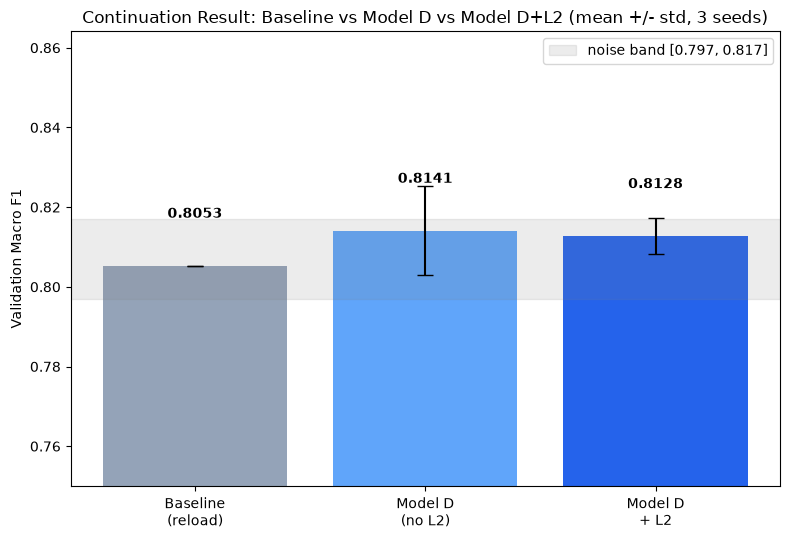

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
configs = ["Baseline\n(reload)", "Model D\n(no L2)", "Model D\n+ L2"]
means = [baseline_f1, d_mean, dl2_mean]
stds = [0.0, d_std, dl2_std]
colors = ["#94A3B8", "#60A5FA", "#2563EB"]
bars = ax.bar(configs, means, yerr=stds, capsize=6, color=colors)
ax.axhspan(NOISE_LOW, NOISE_HIGH, color="gray", alpha=0.15, label=f"noise band [{NOISE_LOW}, {NOISE_HIGH}]")
for b, m in zip(bars, means):
    ax.text(b.get_x() + b.get_width()/2, m + 0.012, f"{m:.4f}", ha="center", fontsize=10, fontweight="bold")
ax.set_ylabel("Validation Macro F1")
ax.set_title("Continuation Result: Baseline vs Model D vs Model D+L2 (mean +/- std, 3 seeds)")
ax.legend()
ax.set_ylim(0.75, max(means) + 0.05)
plt.tight_layout()
plt.savefig(P2_FIGURES / "continuation_result_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


Per-class F1, Model D (no L2) (representative seed=123, macro_f1=0.8188):
 Class | Baseline F1 |  This config F1 |   Change
     0 |       0.929 |           0.933 |   +0.004
     1 |       0.684 |           0.089 |   -0.595  <-- watch
     2 |       0.021 |           0.643 |   +0.623  <-- watch
     3 |       0.986 |           0.988 |   +0.002
     4 |       0.779 |           0.818 |   +0.039
     5 |       0.774 |           0.778 |   +0.004
     6 |       0.978 |           0.985 |   +0.007
     7 |       0.922 |           0.949 |   +0.027
     8 |       0.911 |           0.939 |   +0.028
     9 |       0.910 |           0.924 |   +0.014
    10 |       0.965 |           0.961 |   -0.004


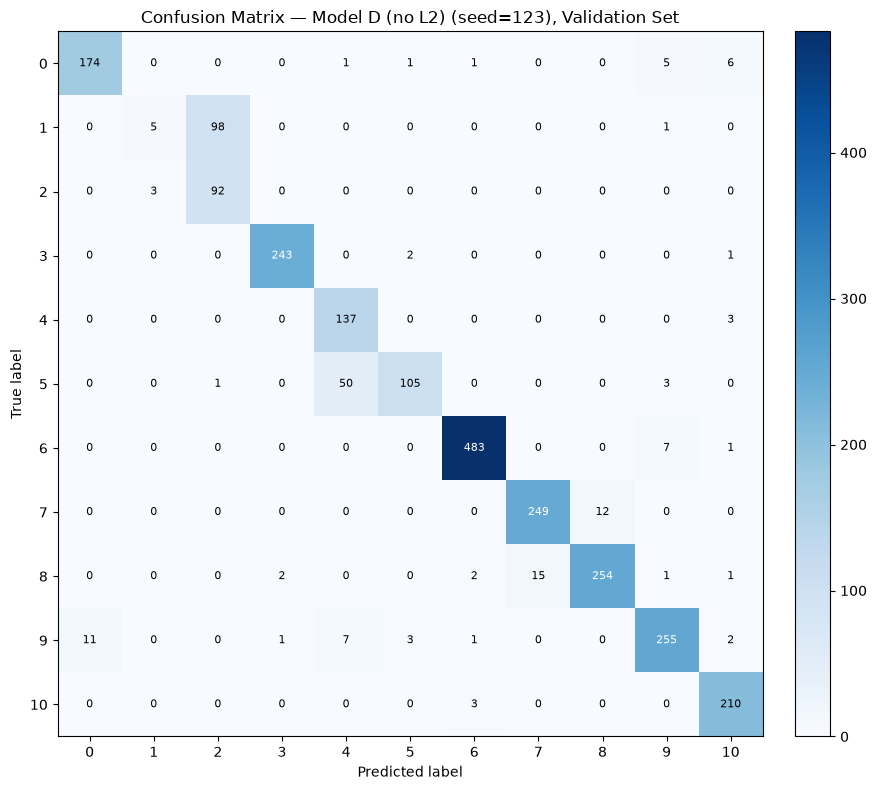

In [11]:
# Per-class F1 for the best confirmed configuration (using the seed closest to that config's mean)
best_results = modeld_l2_results if best_config == "Model D + L2" else modeld_results
closest_seed = min(SEEDS, key=lambda s: abs(best_results[s]["macro_f1"] - best_mean))
best_res = best_results[closest_seed]

print(f"Per-class F1, {best_config} (representative seed={closest_seed}, macro_f1={best_res['macro_f1']:.4f}):")
print(f"{'Class':>6} | {'Baseline F1':>11} | {'This config F1':>15} | {'Change':>8}")
for c, f_base, f_new in zip(classes_sorted, res_baseline["per_f1"], best_res["per_f1"]):
    flag = "  <-- watch" if c in (1, 2) else ""
    print(f"{c:>6} | {f_base:>11.3f} | {f_new:>15.3f} | {f_new-f_base:>+8.3f}{flag}")

cm_best = best_res["cm"]
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_best, cmap="Blues")
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title(f"Confusion Matrix — {best_config} (seed={closest_seed}), Validation Set")
for i in range(n_classes):
    for j in range(n_classes):
        v = cm_best[i, j]
        ax.text(j, i, str(v), ha="center", va="center", color="white" if v > cm_best.max()/2 else "black", fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(P2_FIGURES / "continuation_best_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()


## Week 7 — Documentation Summary


In [12]:
print("=== CONTINUATION RESULT SUMMARY ===")
print(f"Baseline (reloaded, reproduction check): Macro F1 = {baseline_f1:.4f}")
print(f"Model D (no L2), 3 seeds:  mean = {d_mean:.4f}, std = {d_std:.4f}")
print(f"Model D + L2, 3 seeds:     mean = {dl2_mean:.4f}, std = {dl2_std:.4f}")
print()
print(f"Documented noise band: [{NOISE_LOW}, {NOISE_HIGH}]")
print()
delta_best = best_mean - baseline_f1
print(f"Best configuration: {best_config}, delta vs baseline = {delta_best:+.4f}")
if best_mean - (dl2_std if best_config == "Model D + L2" else d_std) > NOISE_HIGH:
    print("VERDICT: mean minus 1 std still clears the noise ceiling -- a defensible, confirmed signal.")
elif best_mean > NOISE_HIGH:
    print("VERDICT: mean clears the noise ceiling but within 1 std of it -- borderline, report honestly as such.")
else:
    print("VERDICT: does not clear the noise ceiling -- this is a legitimate negative/inconclusive result, not a failure of process.")
print()
print("Test set: NOT accessed anywhere in this notebook. Week 8 (final test evaluation) requires explicit approval before proceeding.")


=== CONTINUATION RESULT SUMMARY ===
Baseline (reloaded, reproduction check): Macro F1 = 0.8053
Model D (no L2), 3 seeds:  mean = 0.8141, std = 0.0111
Model D + L2, 3 seeds:     mean = 0.8128, std = 0.0044

Documented noise band: [0.797, 0.817]

Best configuration: Model D (no L2), delta vs baseline = +0.0088
VERDICT: does not clear the noise ceiling -- this is a legitimate negative/inconclusive result, not a failure of process.

Test set: NOT accessed anywhere in this notebook. Week 8 (final test evaluation) requires explicit approval before proceeding.
